# DWD-Wetterdaten Berlin-Dahlem ab 2020

Dieses Notebook lädt tägliche Messdaten der DWD-Station **Berlin-Dahlem (FU, 00403)** herunter, speichert die gewünschten Spalten als CSV und prüft ihre Verfügbarkeit. Zeitraum: **1. Januar 2020 bis zum letzten verfügbaren DWD-Datum**.

Zum Schluss zeigt ein Liniendiagramm die Tagesmitteltemperatur der einzelnen Jahre auf einer gemeinsamen Kalenderachse.

## Datenquelle und Messgrößen

Verwendet werden die DWD-Tageswerte für Klima (KL), Station 00403. Die DWD-Kürzel bedeuten: `TNK` Tagesminimum, `TXK` Tagesmaximum, `TMK` Tagesmitteltemperatur, `RSK` Niederschlagssumme und `SDK` Sonnenscheindauer in Stunden.

DWD kennzeichnet fehlende Messwerte mit `-999`. In der CSV werden solche Werte als leere Felder gespeichert. **Leer bedeutet nicht null.** Die Datenverfügbarkeit wird in diesem Notebook pro Messgröße und Jahr geprüft.

## Benötigte Pakete

Die Zelle installiert pandas für das Einlesen und Zusammenführen der Tabellen sowie requests für den DWD-Download. Führe die Zellen anschließend der Reihe nach mit **Shift+Enter** aus.

In [53]:
%pip install pandas requests matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [54]:
from pathlib import Path
import io
import zipfile

import matplotlib.pyplot as plt
import pandas as pd
import requests
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## DWD-Dateien laden und als CSV speichern

Der DWD stellt ältere qualitätsgeprüfte Daten und jüngere, laufend aktualisierte Daten getrennt bereit. Die Dateien überschneiden sich; beim Zusammenführen verwenden wir für gleiche Tage den Eintrag aus der aktuellen Datei. Das DWD-Original wird im Speicher aus dem ZIP gelesen, die gefilterte Tabelle als CSV im selben Ordner wie dieses Notebook abgelegt.

In [55]:
historisch_url = "https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/historical/tageswerte_KL_00403_19500101_20251231_hist.zip"
aktuell_url = "https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/recent/tageswerte_KL_00403_akt.zip"
spalten_dwd = ["MESS_DATUM", "TNK", "TXK", "TMK", "RSK", "SDK"]


def lade_dwd_zip(url):
    antwort = requests.get(url, timeout=90)
    antwort.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(antwort.content)) as archiv:
        csv_name = next(
            name for name in archiv.namelist()
            if name.startswith("produkt_klima_tag_") and name.endswith(".txt")
        )
        with archiv.open(csv_name) as datei:
            return pd.read_csv(
                datei,
                sep=";",
                skipinitialspace=True,
                usecols=spalten_dwd,
                dtype={"MESS_DATUM": "string"},
                na_values=[-999, "-999"],
            )


dwd_historisch = lade_dwd_zip(historisch_url)
dwd_aktuell = lade_dwd_zip(aktuell_url)

daten = pd.concat([dwd_historisch, dwd_aktuell], ignore_index=True)
daten = daten.drop_duplicates(subset="MESS_DATUM", keep="last")
daten["Datum"] = pd.to_datetime(daten.pop("MESS_DATUM"), format="%Y%m%d")
daten = daten[daten["Datum"] >= "2020-01-01"].sort_values("Datum")

letztes_datum = daten["Datum"].max()
kalender = pd.date_range("2020-01-01", letztes_datum, freq="D", name="Datum")
daten = daten.set_index("Datum").reindex(kalender).reset_index()

daten = daten.rename(columns={
    "TNK": "Temperatur_Min_C",
    "TXK": "Temperatur_Max_C",
    "TMK": "Temperatur_Mittel_C",
    "RSK": "Niederschlagsmenge_mm",
    "SDK": "Sonnenstunden_h",
})
daten = daten[[
    "Datum",
    "Temperatur_Min_C",
    "Temperatur_Max_C",
    "Temperatur_Mittel_C",
    "Niederschlagsmenge_mm",
    "Sonnenstunden_h",
]]

dateiname = "Berlin_Dahlem_DWD_seit_2020.csv"
csv_pfad = Path.cwd() / dateiname
daten.to_csv(csv_pfad, index=False, date_format="%Y-%m-%d", na_rep="", float_format="%.1f")

print(f"CSV gespeichert: {csv_pfad}")
print(f"Zeilen: {len(daten)} | Zeitraum: {daten['Datum'].min().date()} bis {daten['Datum'].max().date()}")
daten.head()

CSV gespeichert: /workspaces/AI_Uebung/Berlin_Dahlem_DWD_seit_2020.csv
Zeilen: 2497 | Zeitraum: 2020-01-01 bis 2026-11-01


,Datum,Temperatur_Min_C,Temperatur_Max_C,Temperatur_Mittel_C,Niederschlagsmenge_mm,Sonnenstunden_h
0,2020-01-01,-2.8,5.0,1.8,0.0,2.9
1,2020-01-02,-4.1,6.2,-0.3,0.0,7.5
2,2020-01-03,0.8,6.9,4.3,4.4,0.0
3,2020-01-04,1.7,5.6,4.1,3.0,0.0
4,2020-01-05,-1.4,3.6,1.4,0.0,2.1


## Verfügbarkeit prüfen

Diese Prüfung zeigt pro Spalte, wie viele Werte tatsächlich vorhanden sind. Danach wird die Sonnenscheindauer je Kalenderjahr gezählt. So sind Stationslücken sichtbar, bevor die Werte später analysiert werden.

In [56]:
feldnamen = {
    "Temperatur_Min_C": "Temperaturminimum (°C)",
    "Temperatur_Max_C": "Temperaturmaximum (°C)",
    "Temperatur_Mittel_C": "Tagesmitteltemperatur (°C)",
    "Niederschlagsmenge_mm": "Niederschlag (mm)",
    "Sonnenstunden_h": "Sonnenscheindauer (h)",
}

verfuegbarkeit = pd.DataFrame({
    "Messgröße": feldnamen.values(),
    "Werte vorhanden": [daten[spalte].notna().sum() for spalte in feldnamen],
    "Werte fehlend": [daten[spalte].isna().sum() for spalte in feldnamen],
}, index=feldnamen.keys())
verfuegbarkeit

,Messgröße,Werte vorhanden,Werte fehlend
Temperatur_Min_C,Temperaturminimum (°C),2481,16
Temperatur_Max_C,Temperaturmaximum (°C),2481,16
Temperatur_Mittel_C,Tagesmitteltemperatur (°C),2481,16
Niederschlagsmenge_mm,Niederschlag (mm),2482,15
Sonnenstunden_h,Sonnenscheindauer (h),2481,16


In [57]:
sonnenstunden_pro_jahr = (
    daten.assign(Jahr=daten["Datum"].dt.year)
    .groupby("Jahr")["Sonnenstunden_h"]
    .agg(Werte_vorhanden="count", Tage="size")
)
sonnenstunden_pro_jahr["Werte_fehlend"] = (
    sonnenstunden_pro_jahr["Tage"] - sonnenstunden_pro_jahr["Werte_vorhanden"]
)
sonnenstunden_pro_jahr

,Werte_vorhanden,Tage,Werte_fehlend
Jahr,,,
2020,366,366,0
2021,365,365,0
2022,365,365,0
2023,365,365,0
2024,366,366,0
2025,349,365,16
2026,305,305,0


## Tagesmitteltemperatur im Jahresvergleich

Jede farbige Linie steht für ein Jahr. Die x-Achse zeigt Monat und Tag statt des vollständigen Datums, damit die Jahreszeiten direkt übereinanderliegen. Fehlende Temperaturwerte bleiben als Lücken in der jeweiligen Linie sichtbar.

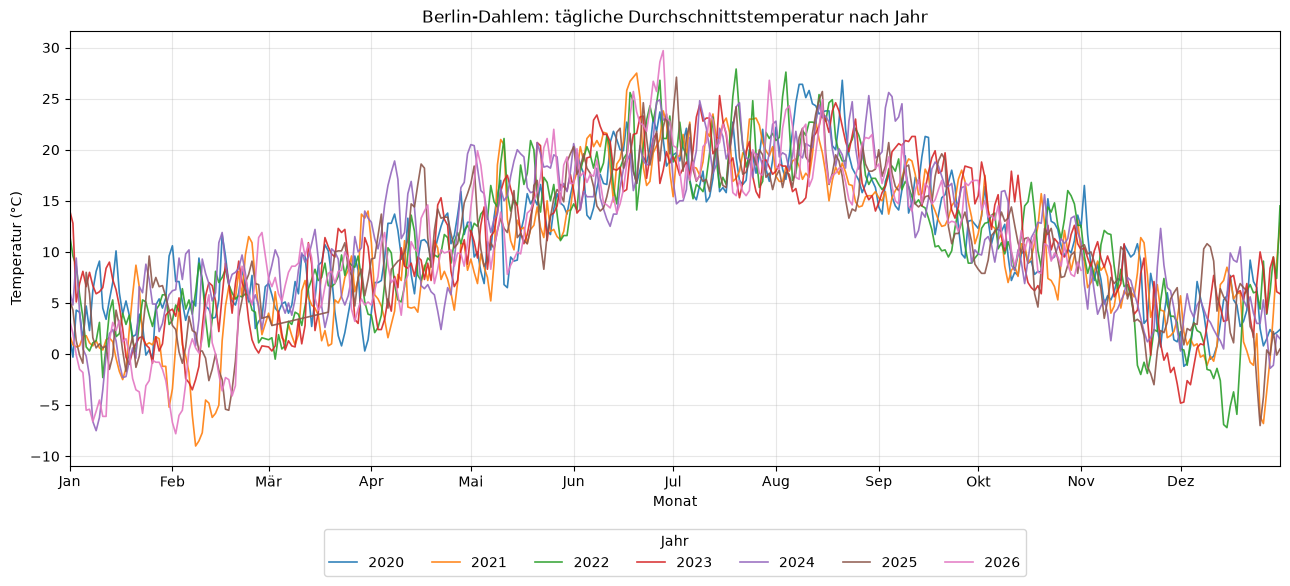

In [58]:
temperatur_plot = daten.dropna(subset=["Temperatur_Mittel_C"]).copy()
temperatur_plot["Jahr"] = temperatur_plot["Datum"].dt.year
temperatur_plot["Tag_im_Jahr"] = pd.to_datetime(
    "2000-" + temperatur_plot["Datum"].dt.strftime("%m-%d"),
    format="%Y-%m-%d",
)

jahre = sorted(temperatur_plot["Jahr"].unique())
farben = plt.get_cmap("tab10").colors
fig, ax = plt.subplots(figsize=(13, 6))

for index, jahr in enumerate(jahre):
    jahresdaten = temperatur_plot[temperatur_plot["Jahr"] == jahr]
    ax.plot(
        jahresdaten["Tag_im_Jahr"],
        jahresdaten["Temperatur_Mittel_C"],
        color=farben[index % len(farben)],
        linewidth=1.2,
        alpha=0.9,
        label=str(jahr),
    )

monatsanfang = pd.date_range("2000-01-01", "2000-12-01", freq="MS")
ax.set_xticks(monatsanfang)
ax.set_xticklabels(["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"])
ax.set_xlim(pd.Timestamp("2000-01-01"), pd.Timestamp("2000-12-31"))
ax.set_title("Berlin-Dahlem: tägliche Durchschnittstemperatur nach Jahr")
ax.set_xlabel("Monat")
ax.set_ylabel("Temperatur (°C)")
ax.grid(True, alpha=0.3)
ax.legend(title="Jahr", ncol=len(jahre), loc="upper center", bbox_to_anchor=(0.5, -0.13))
fig.tight_layout()
plt.show()

Mittlere Spannweite Winter (Dez–Feb): 4.8 °C
Mittlere Spannweite Sommer (Jun–Aug): 2.9 °C
Winter/Sommer-Verhältnis: 1.65


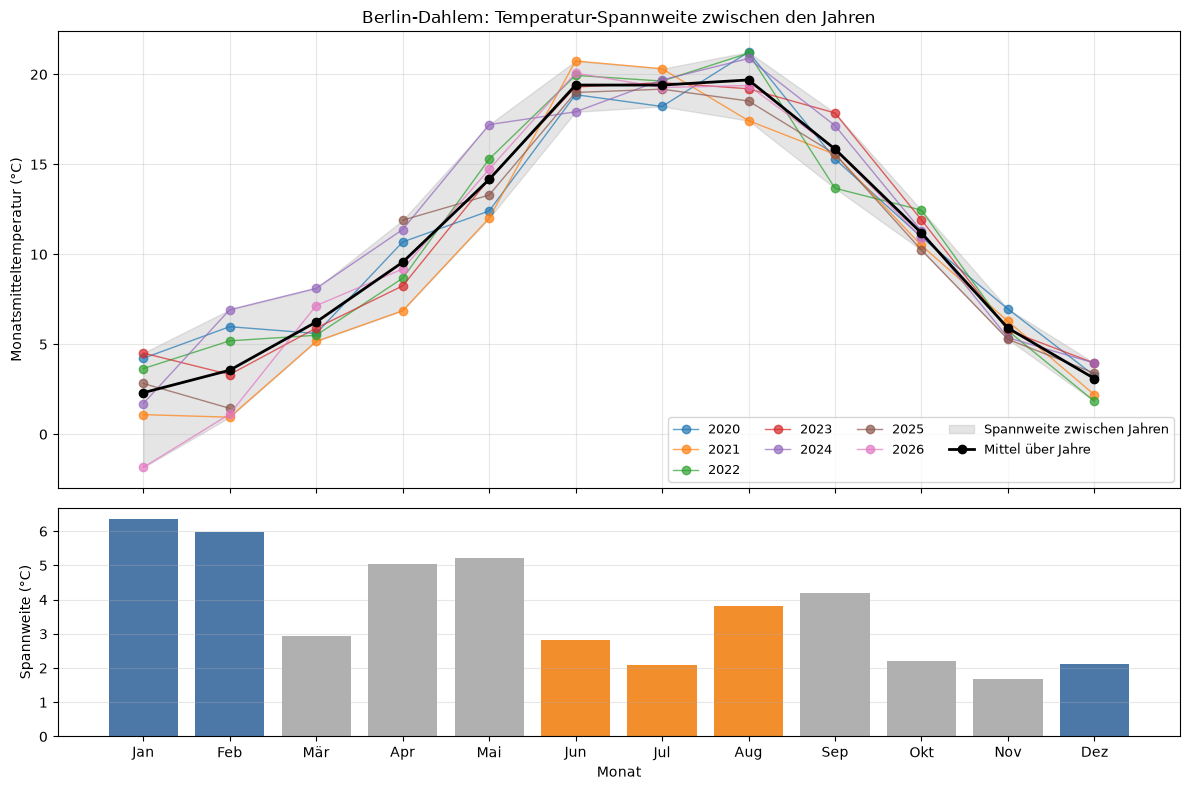

In [59]:
monatstabelle = (
    daten.assign(
        Jahr=daten["Datum"].dt.year,
        Monat=daten["Datum"].dt.month,
        Solltage=daten["Datum"].dt.days_in_month,
    )
    .groupby(["Jahr", "Monat"])
    .agg(
        Monatsmittel=("Temperatur_Mittel_C", "mean"),
        Werte_vorhanden=("Temperatur_Mittel_C", "count"),
        Solltage=("Solltage", "first"),
    )
    .reset_index()
)

# Unvollständige Monate und Monate mit größeren Datenlücken ausschließen
monatstabelle = monatstabelle[
    monatstabelle["Werte_vorhanden"] >= 0.8 * monatstabelle["Solltage"]
]

monatswerte = monatstabelle.pivot(
    index="Jahr", columns="Monat", values="Monatsmittel"
).reindex(columns=range(1, 13))

monats_min = monatswerte.min(axis=0)
monats_max = monatswerte.max(axis=0)
monats_spannweite = monats_max - monats_min
monats_mittel = monatswerte.mean(axis=0)

winter_spannweite = monats_spannweite.loc[[12, 1, 2]].mean()
sommer_spannweite = monats_spannweite.loc[[6, 7, 8]].mean()

print(f"Mittlere Spannweite Winter (Dez–Feb): {winter_spannweite:.1f} °C")
print(f"Mittlere Spannweite Sommer (Jun–Aug): {sommer_spannweite:.1f} °C")
if sommer_spannweite > 0:
    print(f"Winter/Sommer-Verhältnis: {winter_spannweite / sommer_spannweite:.2f}")

monatsnamen = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun",
               "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]
wintermonate = {12, 1, 2}
sommermonate = {6, 7, 8}
balkenfarben = [
    "#4C78A8" if monat in wintermonate
    else "#F28E2B" if monat in sommermonate
    else "#B0B0B0"
    for monat in range(1, 13)
]

fig, (ax_band, ax_spannweite) = plt.subplots(
    2, 1, figsize=(12, 8), sharex=True,
    gridspec_kw={"height_ratios": [2, 1]},
)

for jahr, werte in monatswerte.iterrows():
    ax_band.plot(range(1, 13), werte, marker="o", linewidth=1, alpha=0.7, label=str(jahr))

ax_band.fill_between(
    range(1, 13), monats_min, monats_max,
    color="gray", alpha=0.2, label="Spannweite zwischen Jahren",
)
ax_band.plot(
    range(1, 13), monats_mittel,
    color="black", linewidth=2, marker="o", label="Mittel über Jahre",
)
ax_band.set_ylabel("Monatsmitteltemperatur (°C)")
ax_band.set_title("Berlin-Dahlem: Temperatur-Spannweite zwischen den Jahren")
ax_band.grid(True, alpha=0.3)
ax_band.legend(ncol=4, fontsize=9)

ax_spannweite.bar(range(1, 13), monats_spannweite, color=balkenfarben)
ax_spannweite.set_ylabel("Spannweite (°C)")
ax_spannweite.set_xlabel("Monat")
ax_spannweite.set_xticks(range(1, 13), monatsnamen)
ax_spannweite.grid(axis="y", alpha=0.3)

fig.tight_layout()
plt.show()

## Typischer Analyseablauf in der Data Analytics

### 1) Data Acquisition & Scope
- Zeitfenster: 2020-01-01 bis 2026-11-01
- Datensatzumfang: 2.497 tägliche Beobachtungen
- Kernvariablen: Temperaturminimum, Temperaturmaximum, Tagesmitteltemperatur, Niederschlag, Sonnenscheindauer
- Datenquelle: DWD, Messstation Berlin-Dahlem (00403)
- Analyseziel: Saisonale Muster, interannuelle Vergleiche und Datenqualitätsprüfung

### 2) Data Tasting & Initial Data Review
- Erste Datenprüfung zur Identifikation von Struktur, Format, Ausreißern und fehlenden Werten
- Prüfung der Datentypen, Zeitstempel und konsistenter Messwerte
- Qualitätsstatus: Hohe Datenabdeckung und konsistente tägliche Zeitreihen
- Fehlende Werte wurden dokumentiert und nicht imputiert

### 3) Data Profiling & Data Quality Assessment
- Temperaturminimum, Temperaturmaximum und Tagesmitteltemperatur: 2.481 gültige Werte
- Niederschlag: 2.482 gültige Werte
- Sonnenscheindauer: 2.481 gültige Werte
- Datenqualität: > 99 % Verfügbarkeit für die Hauptmessgrößen
- Keine systematischen Datenlücken im relevanten Analysezeitraum

### 4) Data Cleaning & Preprocessing
- Harmonisierung der Datumswerte und Bereinigung der Zeitachse
- Behandlung von fehlenden Werten als definierte Lücken
- Standardisierung der Messgrößen und Sicherstellung der Analysefähigkeit
- Filterung für den betrachteten Zeitraum ab 2020

### 5) Exploratory Data Analysis (EDA)
- Deskriptive Analyse bestätigt einen klaren saisonalen Temperaturverlauf
- Die niedrigsten Tagesmitteltemperaturen treten überwiegend im Winter auf
- Die höchsten Werte werden in den Sommermonaten erreicht
- Jahresreihen auf gemeinsamer Kalenderachse ermöglichen direkte saisonale Vergleiche

### 6) Time Series Analysis & Seasonal Pattern Analysis
- Monatsmittelwerte zeigen ein typisches Jahresmuster mit Sommermaximum und Winterminimum
- Die größte interannuelle Spannweite tritt im Winter und in Übergangsmonaten auf
- Winter-Spannweite: ca. 4.8 °C
- Sommer-Spannweite: ca. 2.9 °C
- Die höhere Variabilität im Winter deutet auf größere saisonale Schwankungen hin

### 7) Statistical Validation & Interpretation
- Die Datengrundlage eignet sich für robuste zeitliche Vergleichsanalysen
- Die Messreihe zeigt konsistente klimatologische Muster über mehrere Jahre
- Einzelne Lücken sind klein und beeinflussen die Gesamtinterpretation nur begrenzt
- Die Ergebnisse sind belastbar und für weiterführende Analysen nutzbar

### 8) Business Intelligence & Insight Generation
- Berlin-Dahlem zeigt ein typisches mitteleuropäisches Klimamuster mit warmen Sommern und kalten Wintern
- Die Analyse liefert belastbare Erkenntnisse zu saisonaler Temperaturentwicklung und Klima-Variabilität
- Die Datensätze sind geeignet für Monitoring, Vergleichsanalysen und Reporting
- Grundlage für weitere KPI- und Dashboard-Analysen

### 9) Next Steps / Advanced Analysis
- Outlier- und Extremwertanalyse
- Korrelationen zwischen Temperatur, Niederschlag und Sonnenscheindauer
- Trend-, Saison- und Residualanalyse
- Statistische Kennzahlen für Monats- und Jahresvergleiche
- Erstellung eines Reporting-Dashboards für langfristige Trendbeobachtung

### 10) Ergebniszusammenfassung
- Der Datensatz erfüllt die Anforderungen einer typischen Data-Analytics-Pipeline im Bereich Zeitreihen und Klimadaten
- Die wichtigsten Muster sind saisonal stabil, nachvollziehbar und fachlich konsistent
- Die Analyse bildet eine solide Grundlage für weiterführende statistische oder modellbasierte Untersuchungen

## Tagesmitteltemperatur mit einem KI-Modell prognostizieren

Wir sagen für jeden Tag die DWD-Tagesmitteltemperatur voraus. Als Eingaben dienen genau fünf vorherige Tagesmitteltemperaturen und der Tag im Jahr (1 bis 365). Das Modell bekommt nur Informationen, die zum Prognosezeitpunkt bereits bekannt wären.

Wir trainieren einen **Random-Forest-Regressor**: Er kombiniert viele Entscheidungsbäume und mittelt deren Vorhersagen. Als Test verwenden wir das jüngste Jahr, das im Datensatz vorkommt; frühere Jahre bleiben vollständig im Training. Damit testen wir auf spätere Daten statt auf zufällig ausgewählte, zeitlich gemischte Tage.

### 1. Trainingsdaten als Zeitfenster aufbauen

Jede Zeile wird zu einem Trainingsbeispiel: `Temp_vor_1_Tag_C` bis `Temp_vor_5_Tagen_C` sind die fünf Eingabewerte, `Tag_im_Jahr` beschreibt die saisonale Position und `Ziel_Temperatur_C` ist der Wert, den das Modell lernen soll. `shift()` richtet die vergangenen Werte auf den jeweiligen Zieltag aus. Zeilen mit fehlenden Temperaturen in diesem Fenster lassen wir weg.

Für Schaltjahre rechnen wir den Tag nach dem 29. Februar um einen Tag zurück. Dadurch liegt `Tag_im_Jahr` immer zwischen 1 und 365.

In [60]:
trainingsdaten = daten[["Datum", "Temperatur_Mittel_C"]].copy()
wochentag_jahr = trainingsdaten["Datum"].dt.day_of_year
schaltjahr_nach_februar = (
    trainingsdaten["Datum"].dt.is_leap_year
    & (trainingsdaten["Datum"].dt.month > 2)
).astype(int)
trainingsdaten["Tag_im_Jahr"] = wochentag_jahr - schaltjahr_nach_februar
trainingsdaten["Ziel_Temperatur_C"] = trainingsdaten["Temperatur_Mittel_C"]

lag_spalten = []
for lag in range(1, 6):
    spalte = f"Temp_t_minus_{lag}_C"
    trainingsdaten[spalte] = trainingsdaten["Temperatur_Mittel_C"].shift(lag)
    lag_spalten.append(spalte)

modell_spalten = ["Tag_im_Jahr", *lag_spalten]
beispiele = trainingsdaten.dropna(
    subset=[*modell_spalten, "Ziel_Temperatur_C"]
).copy()
beispiele["Jahr"] = beispiele["Datum"].dt.year

print(f"Verwendbare Trainingsbeispiele: {len(beispiele)}")
beispiele[["Datum", *modell_spalten, "Ziel_Temperatur_C"]].head()

Verwendbare Trainingsbeispiele: 2471


,Datum,Tag_im_Jahr,Temp_t_minus_1_C,Temp_t_minus_2_C,Temp_t_minus_3_C,Temp_t_minus_4_C,Temp_t_minus_5_C,Ziel_Temperatur_C
5,2020-01-06,6,1.4,4.1,4.3,-0.3,1.8,4.7
6,2020-01-07,7,4.7,1.4,4.1,4.3,-0.3,2.3
7,2020-01-08,8,2.3,4.7,1.4,4.1,4.3,6.2
8,2020-01-09,9,6.2,2.3,4.7,1.4,4.1,8.1
9,2020-01-10,10,8.1,6.2,2.3,4.7,1.4,9.1


### 2. Training und Test zeitlich trennen

Ein zufälliger Split wäre bei Zeitreihen ungeeignet, weil dabei spätere Tage im Training landen könnten. Wir reservieren deshalb das jüngste Jahr komplett als Testjahr und trainieren nur auf den Jahren davor. So messen wir, wie gut das Modell auf spätere, noch nicht zum Training verwendete Tage überträgt.

In [61]:
test_jahr = int(beispiele["Jahr"].max())
train_beispiele = beispiele[beispiele["Jahr"] < test_jahr].copy()
test_beispiele = beispiele[beispiele["Jahr"] == test_jahr].copy()

X_train = train_beispiele[modell_spalten]
y_train = train_beispiele["Ziel_Temperatur_C"]
X_test = test_beispiele[modell_spalten]
y_test = test_beispiele["Ziel_Temperatur_C"]

print(f"Trainingsjahre: {train_beispiele['Jahr'].min()} bis {train_beispiele['Jahr'].max()}")
print(f"Testjahr: {test_jahr}")
print(f"Trainingsbeispiele: {len(train_beispiele)} | Testbeispiele: {len(test_beispiele)}")
print(f"Testzeitraum: {test_beispiele['Datum'].min().date()} bis {test_beispiele['Datum'].max().date()}")

Trainingsjahre: 2020 bis 2025
Testjahr: 2026
Trainingsbeispiele: 2166 | Testbeispiele: 305
Testzeitraum: 2026-01-01 bis 2026-11-01


### 3. Random-Forest-Modell trainieren

Der Random Forest baut viele Entscheidungsbäume auf unterschiedlichen Teilmengen der Trainingsdaten. Für eine Vorhersage mittelt er deren Ergebnisse. `random_state` sorgt dafür, dass der Trainingslauf reproduzierbar ist; `min_samples_leaf=2` bremst sehr spezifische Einzelregeln etwas aus.

In [62]:
modell = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1,
)
modell.fit(X_train, y_train)
prognose = modell.predict(X_test)

print(f"Modell trainiert: {len(X_train)} Trainingsbeispiele, {len(modell_spalten)} Eingabemerkmale.")

Modell trainiert: 2166 Trainingsbeispiele, 6 Eingabemerkmale.


### 4. Genauigkeit auf dem Testjahr messen

Der **MAE** ist der durchschnittliche absolute Fehler in °C, der **RMSE** gewichtet größere Fehler stärker. **R²** beschreibt, wie viel der Temperaturschwankung das Modell erklärt (1 ist ideal; ein Wert unter 0 ist schlechter als eine konstante Mittelwertvorhersage).

Zum Vergleich berechnen wir eine einfache Baseline: Für jeden Testtag sagen wir die Temperatur des Vortags voraus. Das ist ein sinnvoller Referenzwert für kurzfristige Wetterprognosen.

In [63]:
baseline_vortag = X_test["Temp_t_minus_1_C"]

metriken = pd.DataFrame(
    {
        "MAE (°C)": [
            mean_absolute_error(y_test, prognose),
            mean_absolute_error(y_test, baseline_vortag),
        ],
        "RMSE (°C)": [
            mean_squared_error(y_test, prognose) ** 0.5,
            mean_squared_error(y_test, baseline_vortag) ** 0.5,
        ],
        "R²": [
            r2_score(y_test, prognose),
            r2_score(y_test, baseline_vortag),
        ],
    },
    index=["Random Forest", "Vortag-Baseline"],
)
metriken.round(2)

,MAE (°C),RMSE (°C),R²
Random Forest,1.72,2.20,0.92
Vortag-Baseline,1.70,2.19,0.92


Ein niedrigerer MAE/RMSE ist besser. Liegt der Random Forest unter der Vortag-Baseline, verbessert er diese einfache Referenz auf dem Testjahr. Die folgende Tabelle und Grafik stellen echte DWD-Werte und Prognosen für das Testjahr gegenüber.

In [64]:
test_ergebnisse = pd.DataFrame({
    "Datum": test_beispiele["Datum"].to_numpy(),
    "Ist_Temperatur_C": y_test.to_numpy(),
    "KI_Prognose_C": prognose,
    "Vortag_Baseline_C": baseline_vortag.to_numpy(),
})
test_ergebnisse.head(10).style.format({
    "Ist_Temperatur_C": "{:.1f}",
    "KI_Prognose_C": "{:.1f}",
    "Vortag_Baseline_C": "{:.1f}",
})

,Datum,Ist_Temperatur_C,KI_Prognose_C,Vortag_Baseline_C
0,2026-01-01 00:00:00,3.3,1.1,0.5
1,2026-01-02 00:00:00,2.0,2.4,3.3
2,2026-01-03 00:00:00,-0.1,1.2,2.0
3,2026-01-04 00:00:00,-1.5,0.3,-0.1
4,2026-01-05 00:00:00,-1.8,-1.3,-1.5
5,2026-01-06 00:00:00,-5.5,-2.3,-1.8
6,2026-01-07 00:00:00,-5.4,-4.2,-5.5
7,2026-01-08 00:00:00,-6.6,-3.5,-5.4
8,2026-01-09 00:00:00,-5.6,-5.9,-6.6
9,2026-01-10 00:00:00,-4.5,-3.1,-5.6


Der Zeitreihenplot macht sichtbar, ob das Modell den Verlauf des Testjahres nachvollzieht. Jede Prognose ist ein **Ein-Tages-Schritt**: Für den nächsten Testtag verwenden wir die tatsächlich gemessenen Temperaturen der fünf vorangegangenen Tage. Das ist keine mehrtägige Vorhersage, bei der Modellprognosen rekursiv als neue Eingaben verwendet werden.

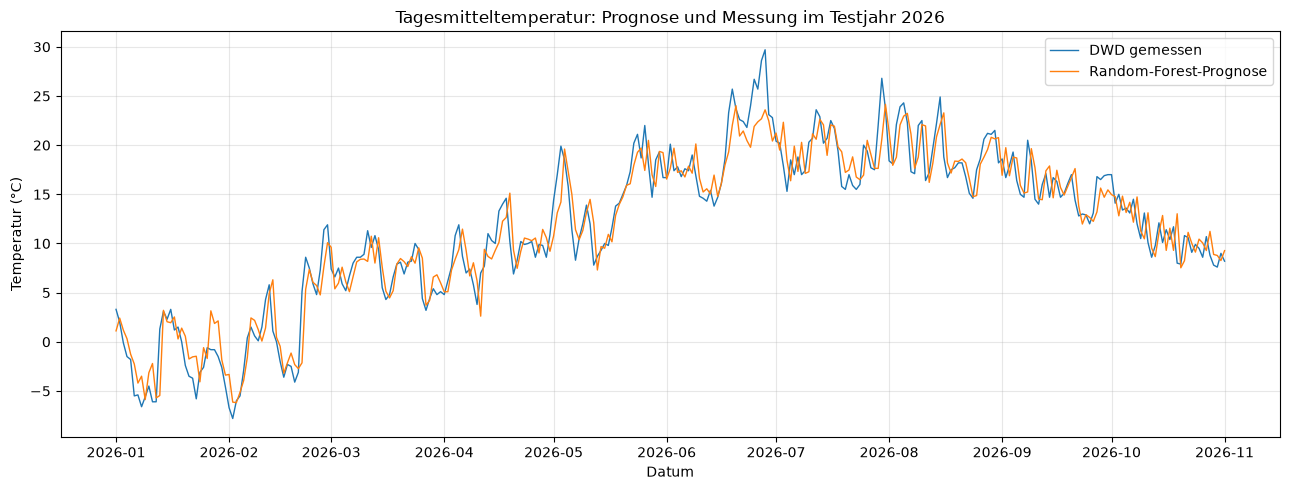

In [65]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(test_ergebnisse["Datum"], test_ergebnisse["Ist_Temperatur_C"], label="DWD gemessen", linewidth=1)
ax.plot(test_ergebnisse["Datum"], test_ergebnisse["KI_Prognose_C"], label="Random-Forest-Prognose", linewidth=1)
ax.set_title(f"Tagesmitteltemperatur: Prognose und Messung im Testjahr {test_jahr}")
ax.set_xlabel("Datum")
ax.set_ylabel("Temperatur (°C)")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

### 5. Ergebnis einordnen und nächsten Tag prognostizieren

Zuerst vergleichen wir die Kennzahlen mit der Vortag-Baseline. Erst **nach** dieser unabhängigen Testauswertung trainieren wir ein finales Modell mit allen verfügbaren Beispielen. Dieses Modell schätzt dann den Tag nach dem letzten DWD-Messwert anhand der fünf unmittelbar vorhergehenden Tagesmitteltemperaturen und des zugehörigen `Tag_im_Jahr`.

Die Prognose ist ein einfacher Modellversuch, keine amtliche Wettervorhersage: Es fehlen wichtige Einflussgrößen wie Luftdruck, Wind, Bewölkung und externe Wettervorhersagen.

In [66]:
mae_random_forest = metriken.loc["Random Forest", "MAE (°C)"]
mae_baseline = metriken.loc["Vortag-Baseline", "MAE (°C)"]
if mae_random_forest < mae_baseline:
    print(f"Der Random Forest verbessert die Vortag-Baseline um {mae_baseline - mae_random_forest:.2f} °C MAE.")
else:
    print(f"Der Random Forest ist beim MAE {mae_random_forest - mae_baseline:.2f} °C schlechter als die Vortag-Baseline.")

letzte_fuenf = daten.tail(5).copy()
if letzte_fuenf["Temperatur_Mittel_C"].isna().any():
    raise ValueError("Für die Prognose müssen die letzten fünf Tagesmitteltemperaturen vorhanden sein.")
if not (letzte_fuenf["Datum"].diff().dropna() == pd.Timedelta(days=1)).all():
    raise ValueError("Die letzten fünf Messwerte müssen von aufeinanderfolgenden Tagen stammen.")

naechster_tag = daten["Datum"].max() + pd.Timedelta(days=1)
tag_im_jahr = naechster_tag.day_of_year
if naechster_tag.is_leap_year and naechster_tag.month > 2:
    tag_im_jahr -= 1

eingabe_naechster_tag = {"Tag_im_Jahr": [tag_im_jahr]}
for lag in range(1, 6):
    eingabe_naechster_tag[f"Temp_t_minus_{lag}_C"] = [
        letzte_fuenf["Temperatur_Mittel_C"].iloc[-lag]
    ]
eingabe_naechster_tag = pd.DataFrame(eingabe_naechster_tag)[modell_spalten]

finales_modell = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1,
)
finales_modell.fit(beispiele[modell_spalten], beispiele["Ziel_Temperatur_C"])
prognose_naechster_tag = finales_modell.predict(eingabe_naechster_tag)[0]

print(f"Letzter Messwert: {daten['Datum'].max().date()}")
naechste_prognose = pd.DataFrame({
    "Prognosedatum": [naechster_tag.date()],
    "Prognose_Tagesmittel_C": [round(prognose_naechster_tag, 1)],
})
naechste_prognose

Der Random Forest ist beim MAE 0.02 °C schlechter als die Vortag-Baseline.
Letzter Messwert: 2026-11-01


,Prognosedatum,Prognose_Tagesmittel_C
0,2026-11-02,8.9
